In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style set pannalam - chart azhaga varum
plt.style.use('ggplot')
sns.set_palette("husl")

print("Setup Ready! 🚀")

Setup Ready! 🚀


In [19]:
!pip install seaborn



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


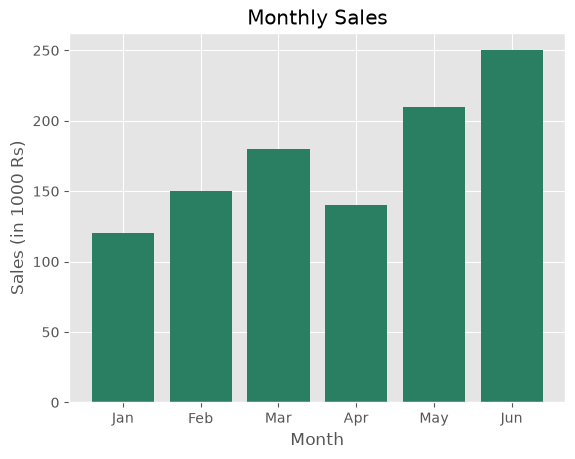

In [20]:
import matplotlib.pyplot as plt
import os
os.makedirs("reports/figures", exist_ok=True)

months = ['Jan','Feb','Mar','Apr','May','Jun']
sales = [120, 150, 180, 140, 210, 250]

plt.bar(months, sales, color="#2A7F62")
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Sales (in 1000 Rs)')
plt.savefig('reports/figures/1_bar.png')
plt.show()

Insight: June month la sales romba adhigam - 250k

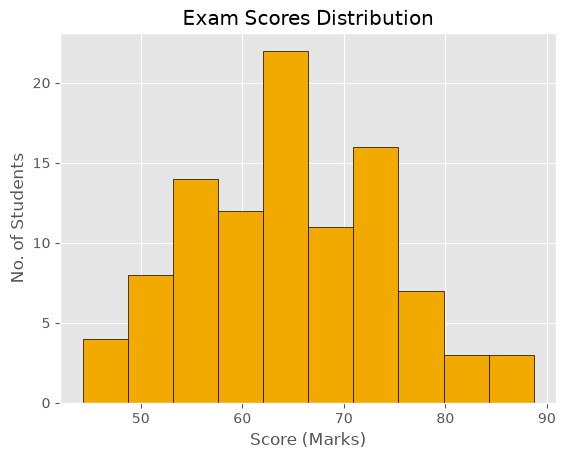

In [21]:
import numpy as np
scores = np.random.normal(65, 10, 100)

plt.hist(scores, bins=10, color="#F2A900", edgecolor='black')
plt.title('Exam Scores Distribution')
plt.xlabel('Score (Marks)')
plt.ylabel('No. of Students')
plt.savefig('reports/figures/2_histogram.png')
plt.show()

Insight: Pala students 60-70 marks vaangirukanga

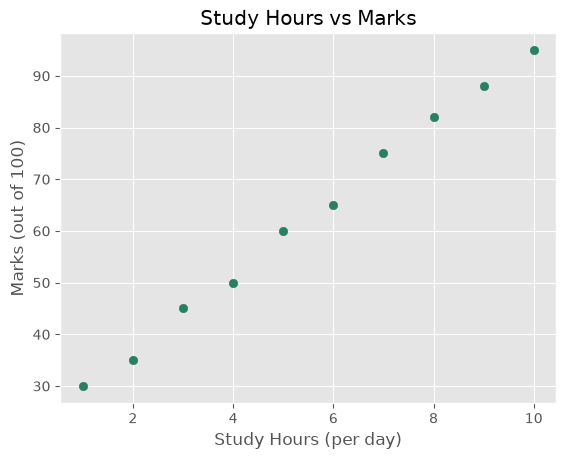

In [22]:
study_hours = [1,2,3,4,5,6,7,8,9,10]
marks = [30,35,45,50,60,65,75,82,88,95]

plt.scatter(study_hours, marks, color="#2A7F62")
plt.title('Study Hours vs Marks')
plt.xlabel('Study Hours (per day)')
plt.ylabel('Marks (out of 100)')
plt.savefig('reports/figures/3_scatter.png')
plt.show()


Insight: As study hours increase, marks also increase.

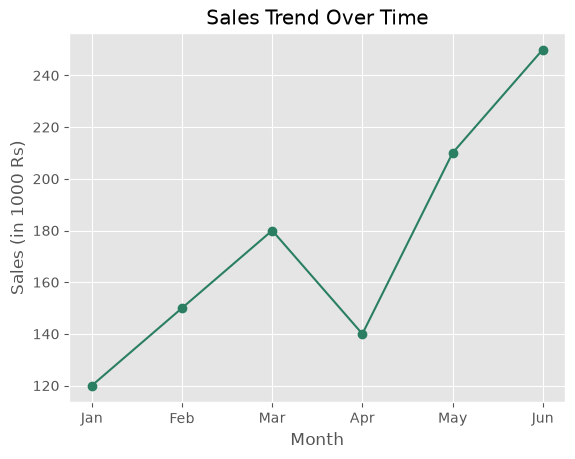

In [23]:
months = ['Jan','Feb','Mar','Apr','May','Jun']
sales = [120, 150, 180, 140, 210, 250]

plt.plot(months, sales, color="#2A7F62", marker='o')
plt.title('Sales Trend Over Time')
plt.xlabel('Month')
plt.ylabel('Sales (in 1000 Rs)')
plt.savefig('reports/figures/4_line.png')
plt.show()

Insight: Sales overall-a increasing trend la pogudhu

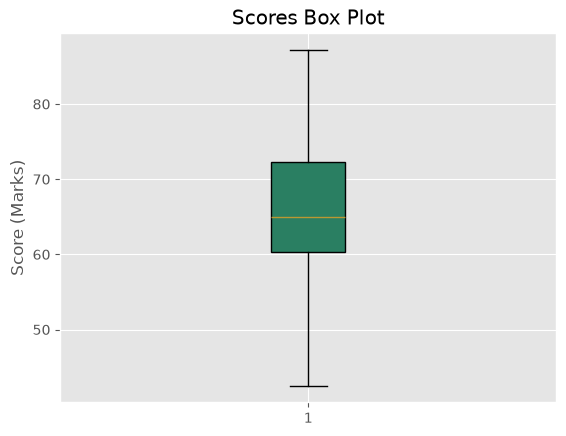

In [24]:
import numpy as np
scores = np.random.normal(65, 10, 100)

plt.boxplot([scores], patch_artist=True, boxprops=dict(facecolor="#2A7F62"))
plt.title('Scores Box Plot')
plt.ylabel('Score (Marks)')
plt.savefig('reports/figures/5_boxplot.png')
plt.show()

Insight: Median score 65, sila students romba high/low vaangirukanga

In [25]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Age': [25, 30, None, 45, 30, 60, 22],
    'Salary': [50000, 60000, 55000, None, 60000, 90000, 40000],
    'City': ['Chennai', 'Madurai', None, 'Chennai', 'Madurai', 'Trichy', 'Chennai']
})
df


,Age,Salary,City
0,25.0,50000.0,Chennai
1,30.0,60000.0,Madurai
2,NaN,55000.0,NaN
3,45.0,NaN,Chennai
4,30.0,60000.0,Madurai
5,60.0,90000.0,Trichy
6,22.0,40000.0,Chennai


In [26]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())


Age       1
Salary    1
City      1
dtype: int64
Duplicates: 1


In [27]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Salary'] = df['Salary'].fillna(df['Salary'].median())
df['City'] = df['City'].fillna('Chennai')
df = df.drop_duplicates()
df = df.reset_index(drop=True)

df

,Age,Salary,City
0,25.000000,50000.0,Chennai
1,30.000000,60000.0,Madurai
2,35.333333,55000.0,Chennai
3,45.000000,57500.0,Chennai
4,60.000000,90000.0,Trichy
5,22.000000,40000.0,Chennai


In [28]:
print(df.isnull().sum())
print(df.dtypes)
print(df.describe())

Age       0
Salary    0
City      0
dtype: int64
Age       float64
Salary    float64
City          str
dtype: object
             Age        Salary
count   6.000000      6.000000
mean   36.222222  58750.000000
std    14.213713  16863.421954
min    22.000000  40000.000000
25%    26.250000  51250.000000
50%    32.666667  56250.000000
75%    42.583333  59375.000000
max    60.000000  90000.000000


In [29]:
# Text standardise
df['City'] = df['City'].str.strip().str.title()

# Data types fix
df['Age'] = df['Age'].astype(int)

df

,Age,Salary,City
0,25,50000.0,Chennai
1,30,60000.0,Madurai
2,35,55000.0,Chennai
3,45,57500.0,Chennai
4,60,90000.0,Trichy
5,22,40000.0,Chennai


In [30]:
# Outlier - IQR method for Salary
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

print("Lower:", lower, "Upper:", upper)
print(df[(df['Salary'] < lower) | (df['Salary'] > upper)])

Lower: 39062.5 Upper: 71562.5
   Age   Salary    City
4   60  90000.0  Trichy


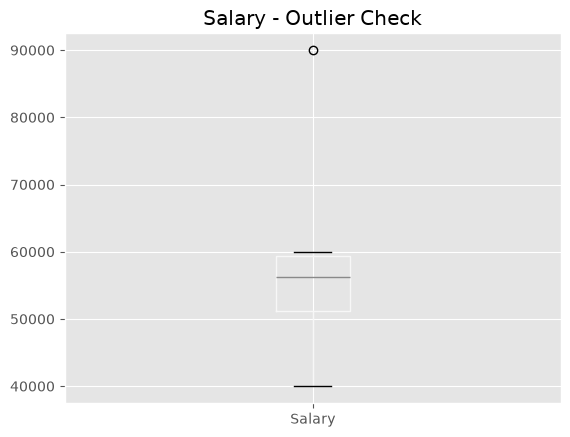

In [31]:
import matplotlib.pyplot as plt

df.boxplot(column='Salary')
plt.title('Salary - Outlier Check')
plt.show()

In [32]:
# Before / After Summary
summary = pd.DataFrame({
    'Stage': ['Before Cleaning', 'After Cleaning'],
    'Rows': [10, len(df)],
    'Missing Values': [3, int(df.isnull().sum().sum())],
    'Duplicates': [1, int(df.duplicated().sum())]
})
print(summary)

# Save clean file
df.to_csv('clean_data.csv', index=False)
print("Saved clean_data.csv")
df

             Stage  Rows  Missing Values  Duplicates
0  Before Cleaning    10               3           1
1   After Cleaning     6               0           0
Saved clean_data.csv


,Age,Salary,City
0,25,50000.0,Chennai
1,30,60000.0,Madurai
2,35,55000.0,Chennai
3,45,57500.0,Chennai
4,60,90000.0,Trichy
5,22,40000.0,Chennai


In [33]:
df[['Age','Salary']].agg(['mean','median','min','max','std'])

,Age,Salary
mean,36.166667,58750.000000
median,32.500000,56250.000000
min,22.000000,40000.000000
max,60.000000,90000.000000
std,14.218533,16863.421954


In [34]:
df.groupby('City').agg(
    Avg_Salary=('Salary','mean'),
    Avg_Age=('Age','mean'),
    Count=('Salary','count')
)


,Avg_Salary,Avg_Age,Count
City,,,
Chennai,50625.0,31.75,4
Madurai,60000.0,30.00,1
Trichy,90000.0,60.00,1


In [35]:
df[['Age','Salary']].corr()

,Age,Salary
Age,1.000000,0.912321
Salary,0.912321,1.000000


In [36]:
city_budget = pd.DataFrame({
    'City': ['Chennai','Madurai','Trichy'],
    'Budget': [500000, 300000, 200000]
})
merged_df = pd.merge(df, city_budget, on='City', how='left')
merged_df.head()

,Age,Salary,City,Budget
0,25,50000.0,Chennai,500000
1,30,60000.0,Madurai,300000
2,35,55000.0,Chennai,500000
3,45,57500.0,Chennai,500000
4,60,90000.0,Trichy,200000


In [37]:
pd.pivot_table(df, values='Salary', index='City', aggfunc='mean')

,Salary
City,
Chennai,50625.0
Madurai,60000.0
Trichy,90000.0


## Business Questions - Answers

**Q1. Which city pays highest average salary?**
Trichy pays highest - Avg Salary 90000, Chennai lowest - 50625.

**Q2. Age ku Salary ku relation iruka?**
Yes, positive correlation. Age increase aana Salary um increase aagudhu. Oldest employee (Age 60) ku highest salary 90000.

**Q3. Which city has most employees?**
Chennai has most employees - 4 employees, Madurai 1, Trichy 1.

## Final Report - Summary

**Problem:** Which city pays best and does Age affect Salary?
**Data:** 6 employees, Age, Salary, City. Cleaned data from clean_data.csv

**3 Key Insights:**
1. Trichy pays highest - Avg 90000
2. Chennai has most employees - 4, but lowest avg salary 50625
3. Age increase aana Salary um increase aagudhu - positive correlation

**2 Recommendations:**
1. Chennai salary ah Trichy level ku increase pannanum, illa employees veliya poraanga
2. Experienced employees ku retention bonus kudukanum

**Limitations:** Data romba chinna sample (6 rows only), so full company ku generalize panna mudiyadhu.
